# 💡 04. Explainable AI (XAI) Suite: SHAP & LIME Interpretability
### Project: XAI System in Banking: AI Anomaly-Driven Credit Card Fraud Detection and Interpretation
**Objective:** Deliver model-agnostic (LIME) and game-theoretic (SHAP) explanations to provide both global insights and individual transaction-level root cause analysis for bank compliance and fraud operations.

In [1]:
import os, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import joblib, shap
from IPython.display import Image, display

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT_DIR))

from src.data.preprocessing import DataPipeline
from src.xai.shap_explainer import FraudSHAPExplainer
from src.xai.lime_explainer import FraudLIMEExplainer

print("XAI Suite initialized.")

/home/swayam-shah/repos/XAI-System-in-Banking-AI-Anomaly-Driven-Credit-Card-Fraud-Detection-and-Interpretation/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


XAI Suite initialized.


## 1. Global Feature Attributions: SHAP Summary & Beeswarm
SHAP Shapley values compute the marginal contribution of each transaction feature across all possible feature subsets.

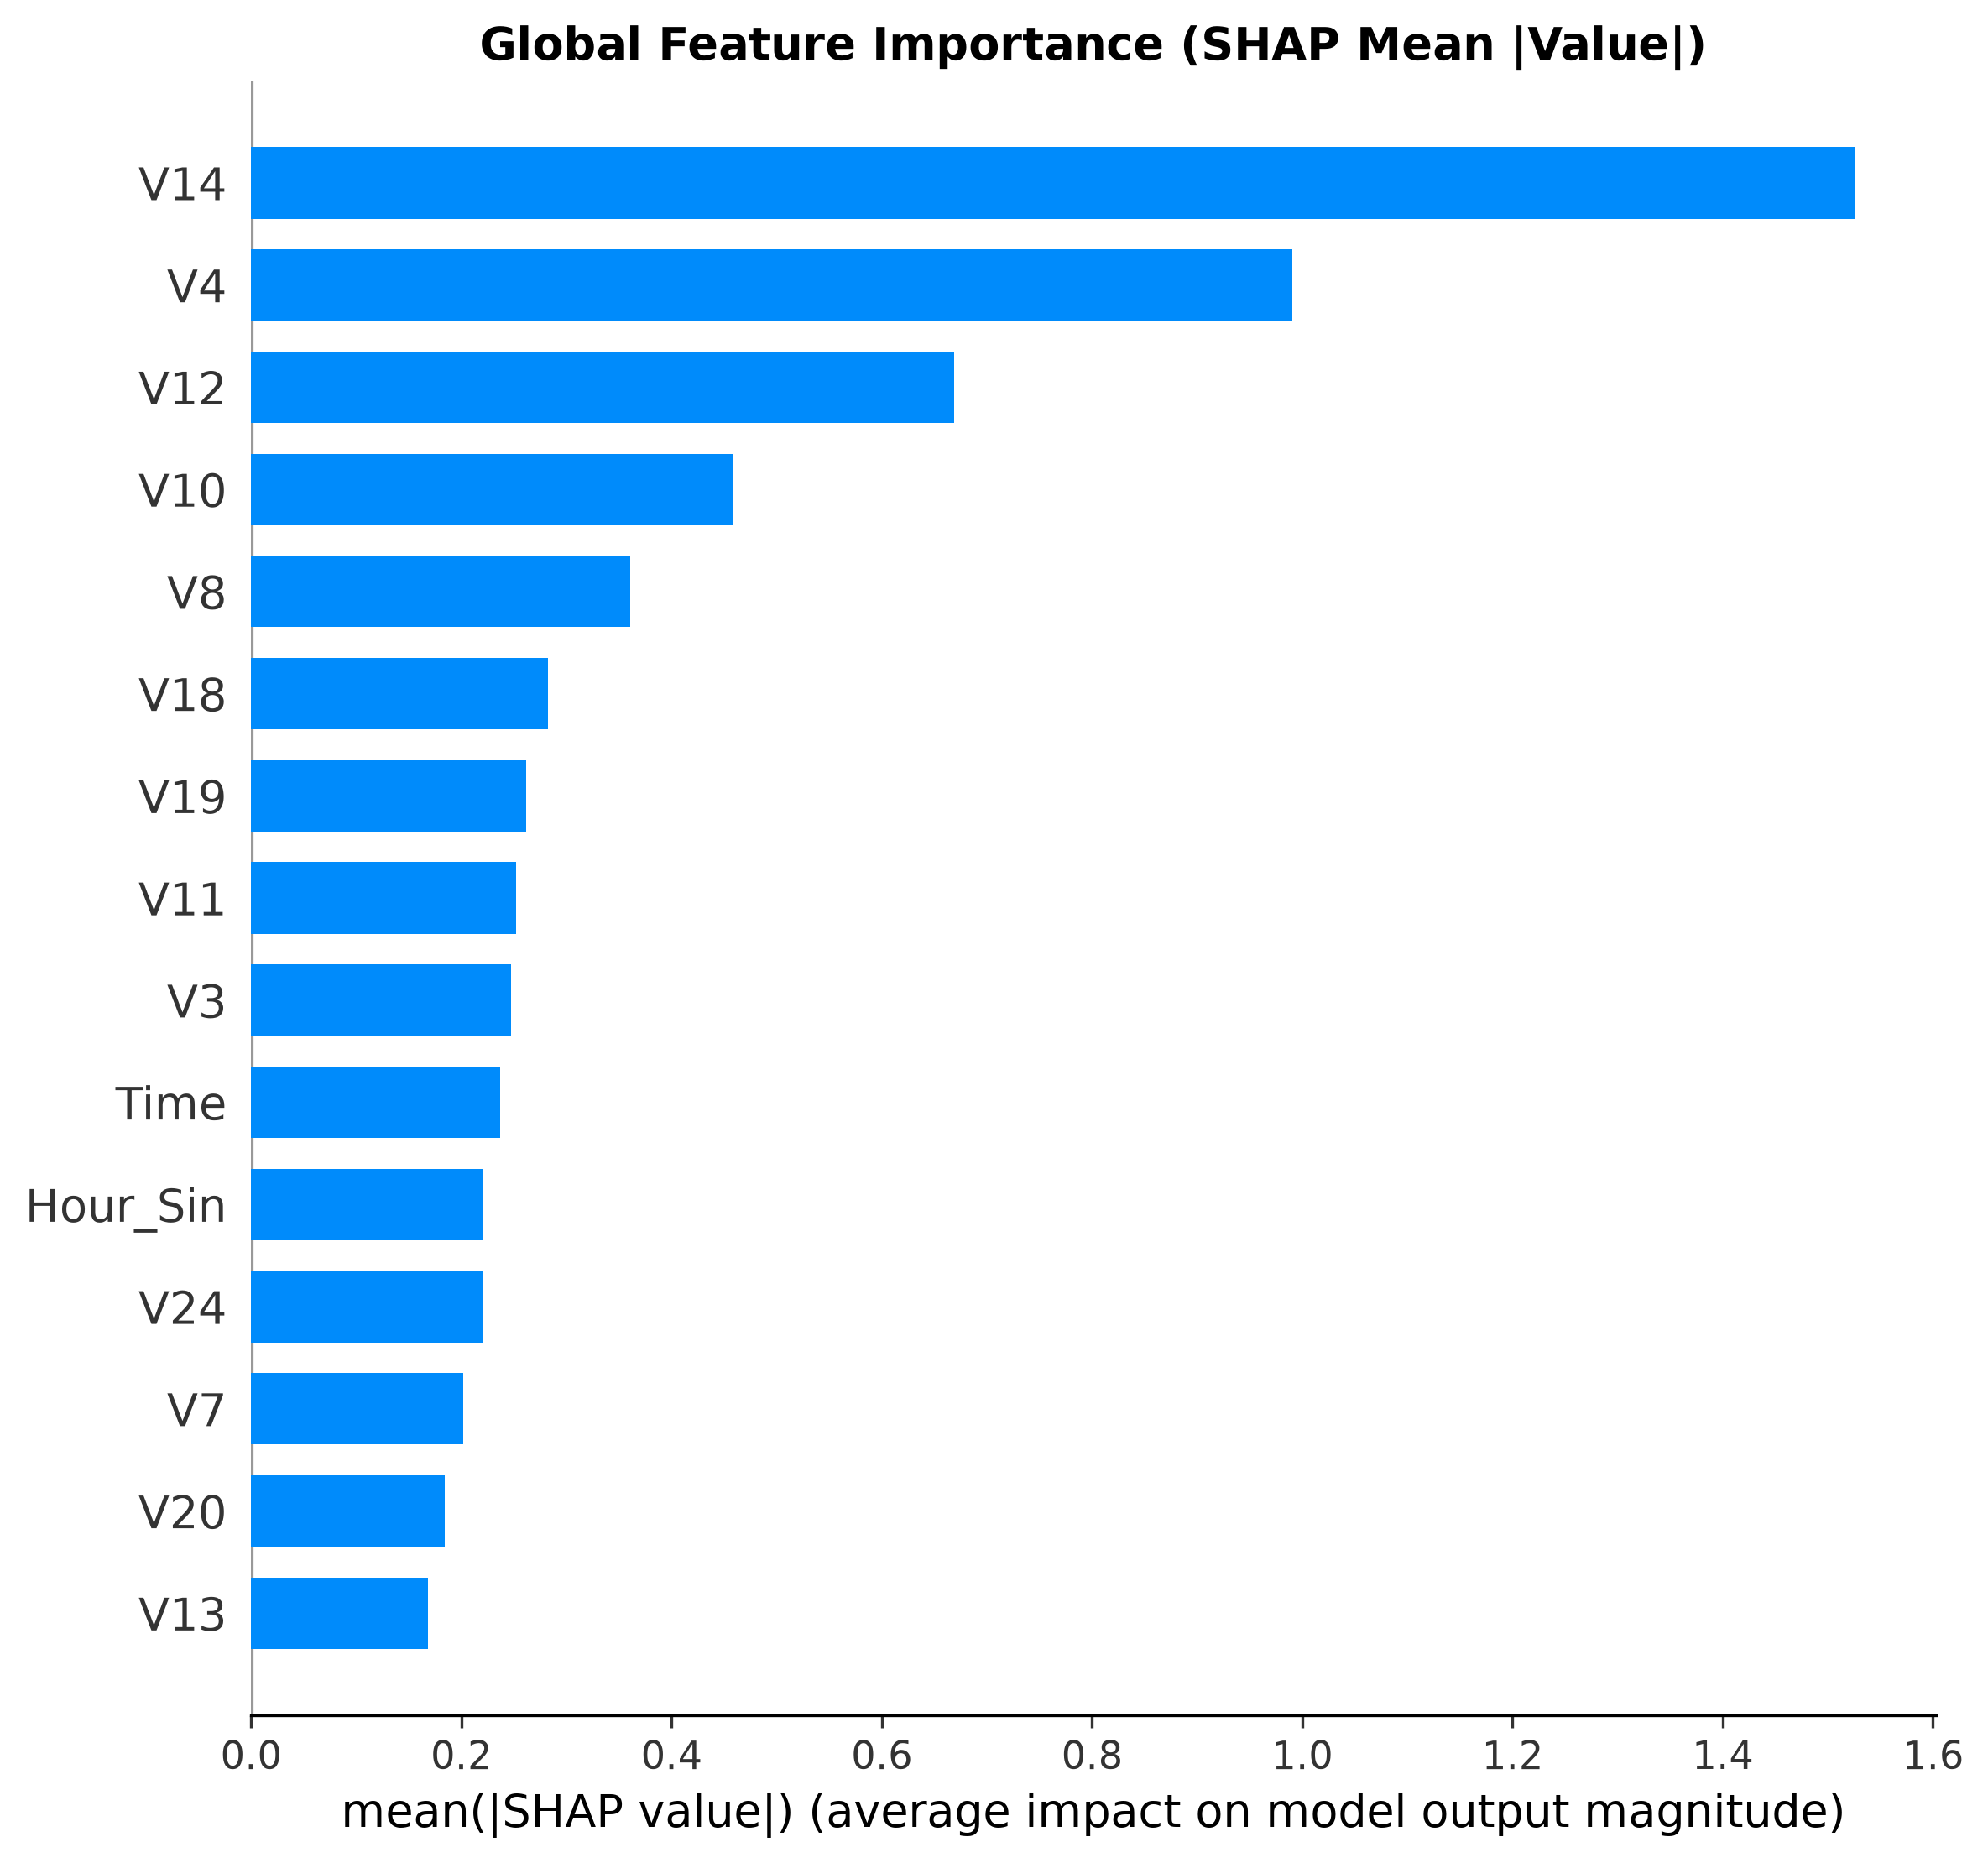

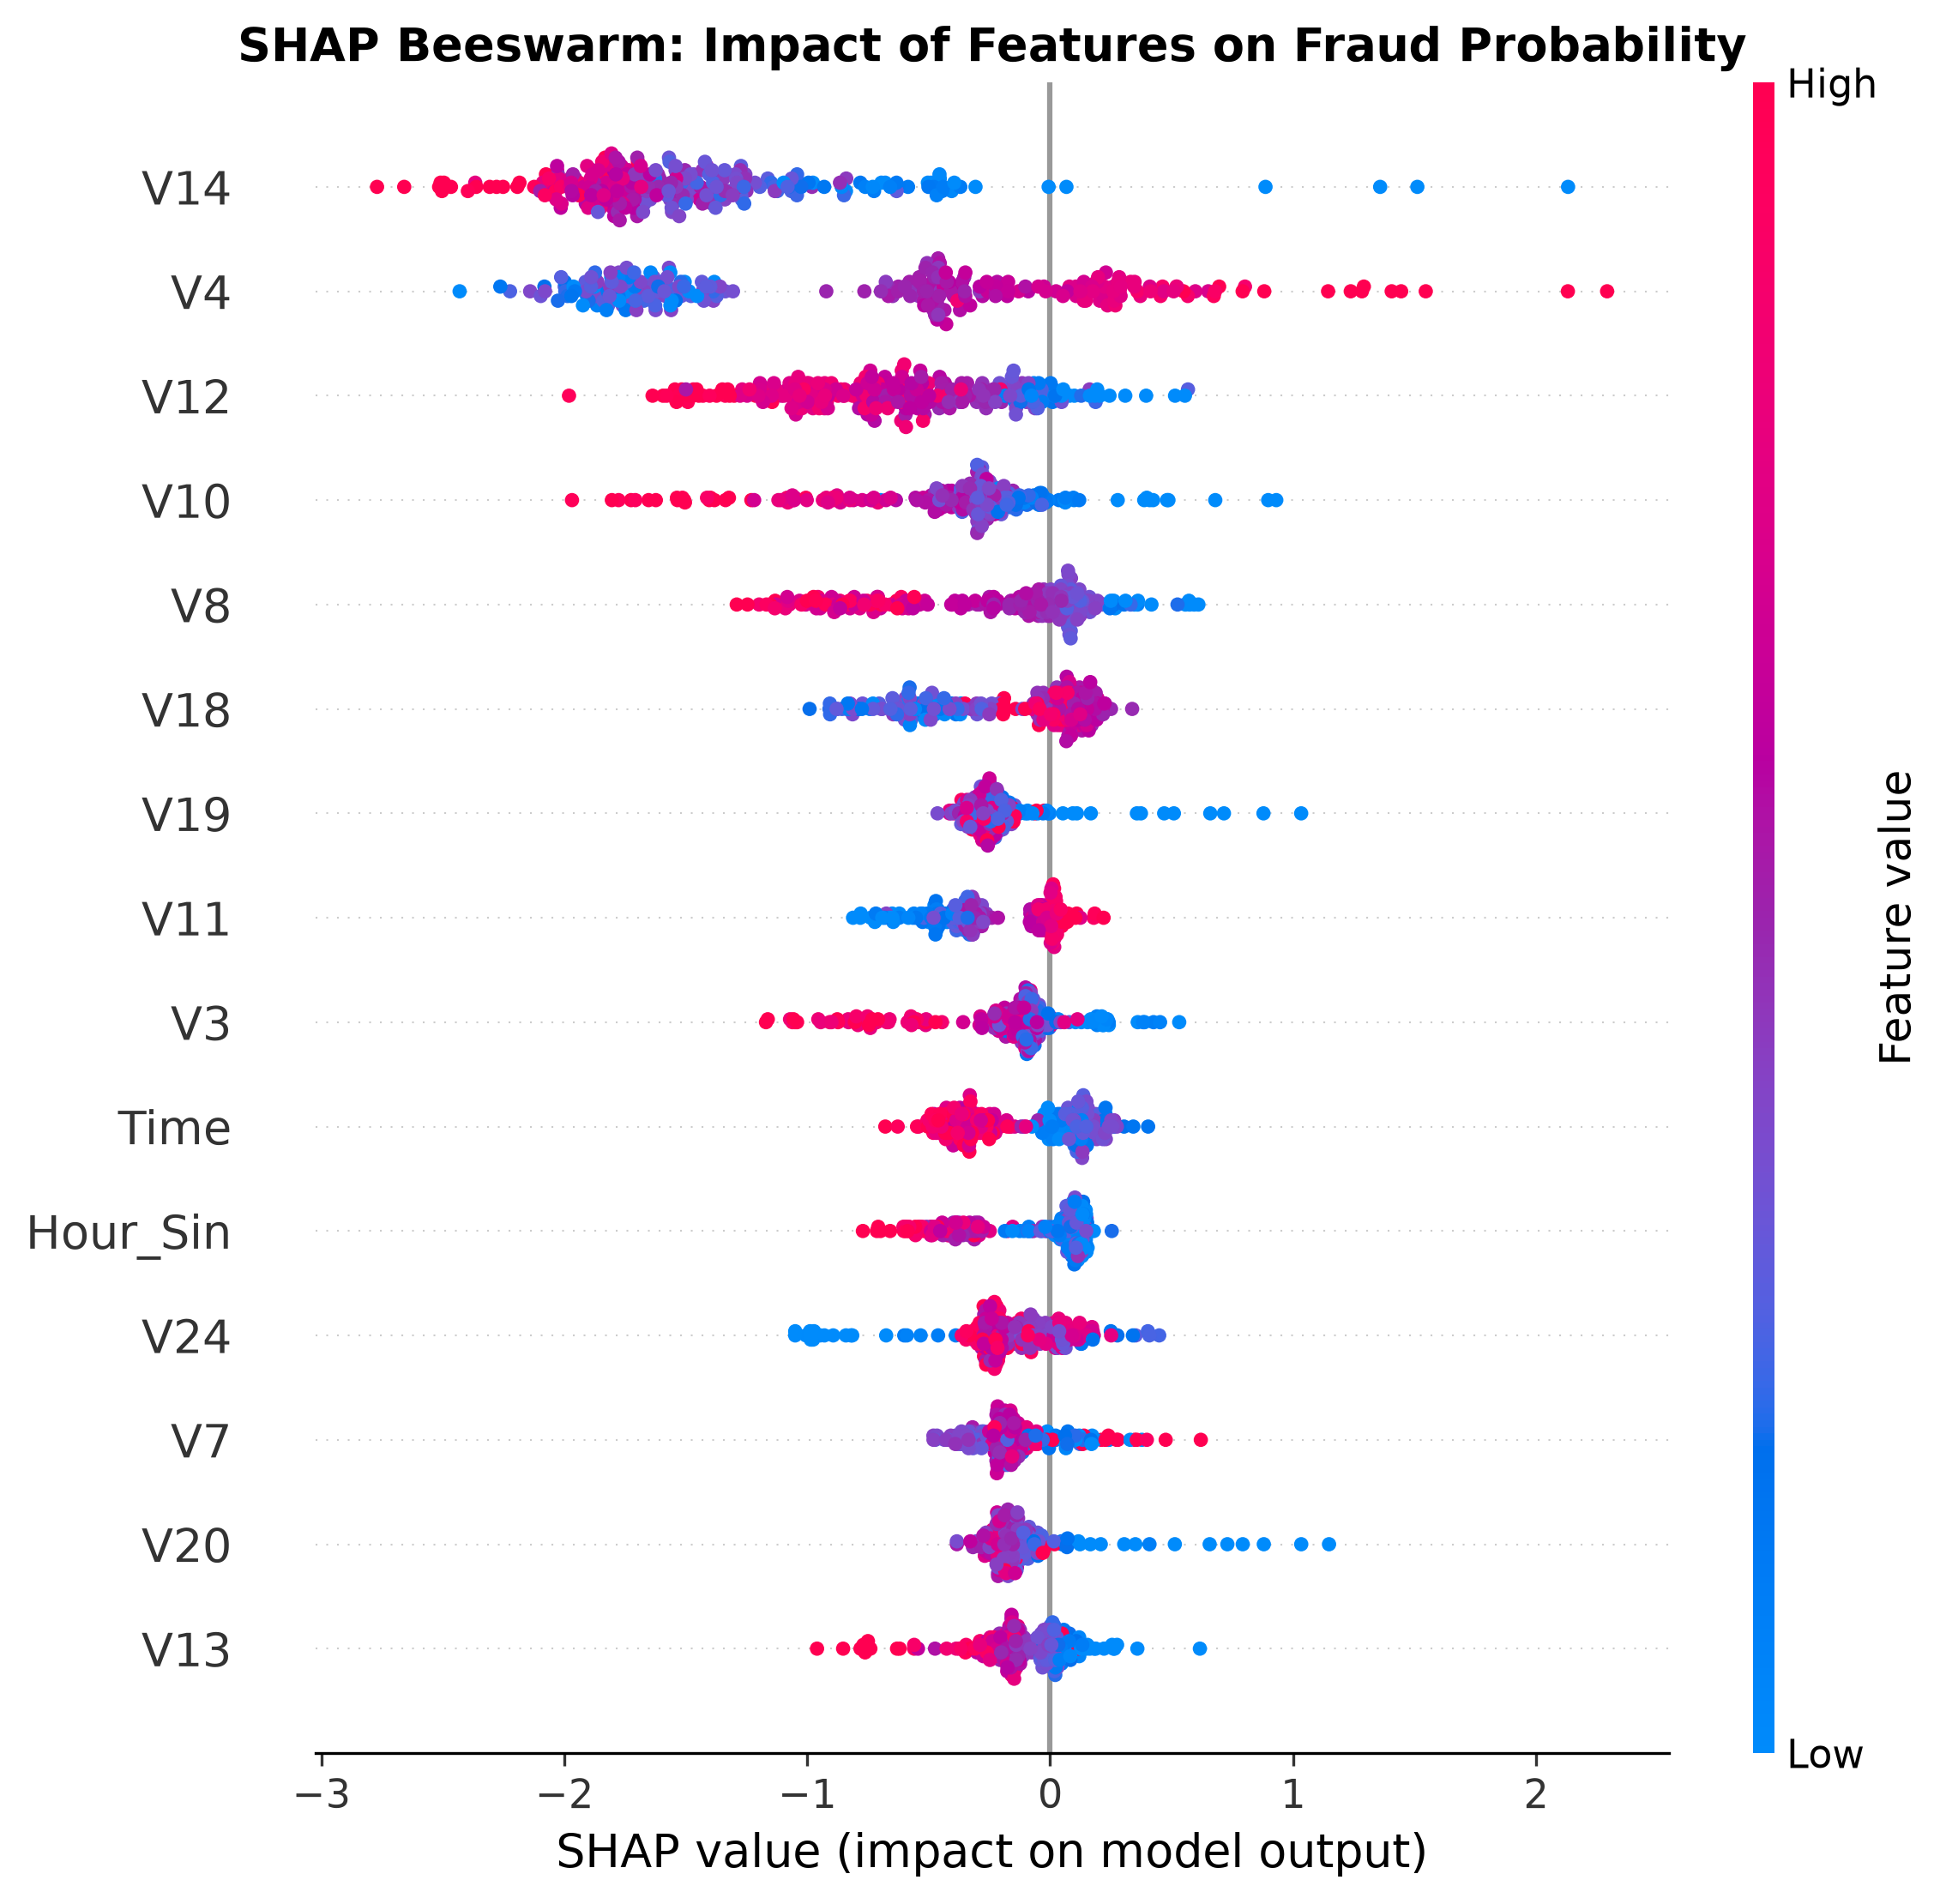

In [2]:
bar_path = ROOT_DIR / "results/explanations/shap_summary_bar.png"
bee_path = ROOT_DIR / "results/explanations/shap_beeswarm.png"

if bar_path.exists():
    display(Image(filename=str(bar_path)))
if bee_path.exists():
    display(Image(filename=str(bee_path)))

## 2. SHAP Partial Dependence Plots
Partial dependence displays how specific feature values non-linearly modulate fraud probability.

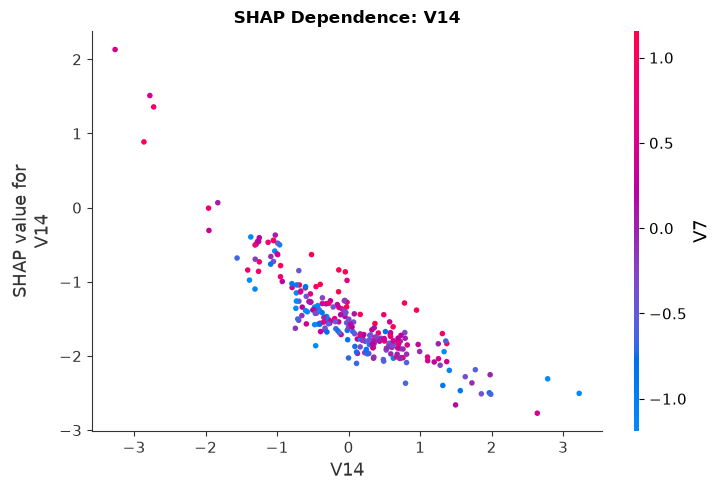

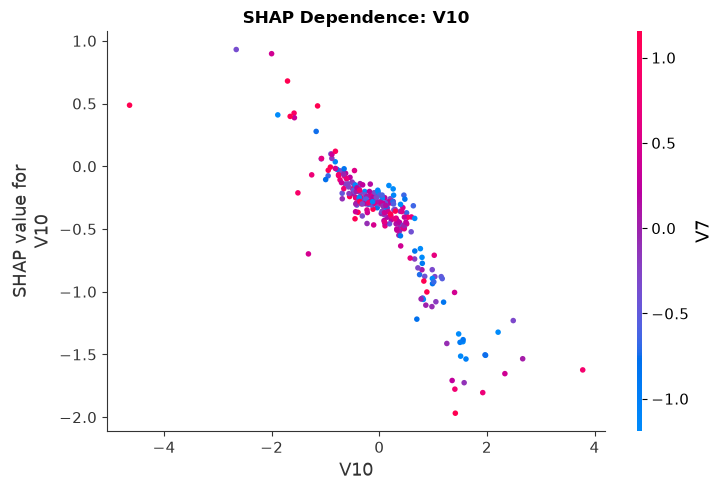

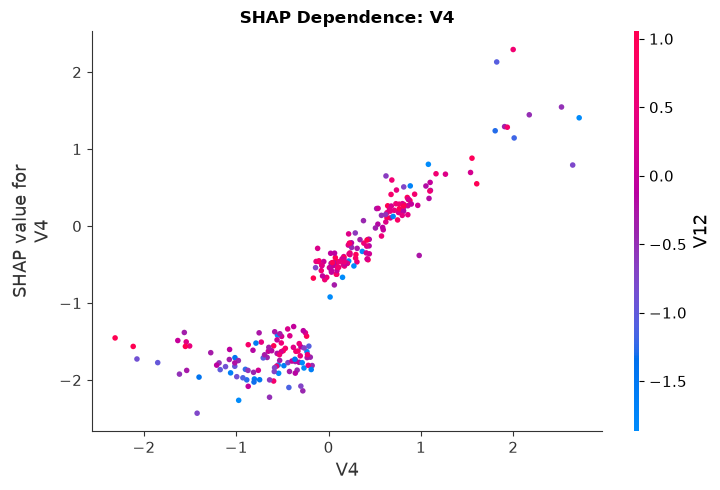

In [3]:
for feat in ["v14", "v10", "v4"]:
    dep_path = ROOT_DIR / f"results/explanations/shap_dependence_{feat}.png"
    if dep_path.exists():
        display(Image(filename=str(dep_path)))

## 3. Local Decision Rationale: SHAP Waterfall Plots
A waterfall plot explains a specific transaction: starting from the base fraud rate, it displays the push-and-pull forces of each feature.

--- Confirmed Fraud Transaction Explanation ---


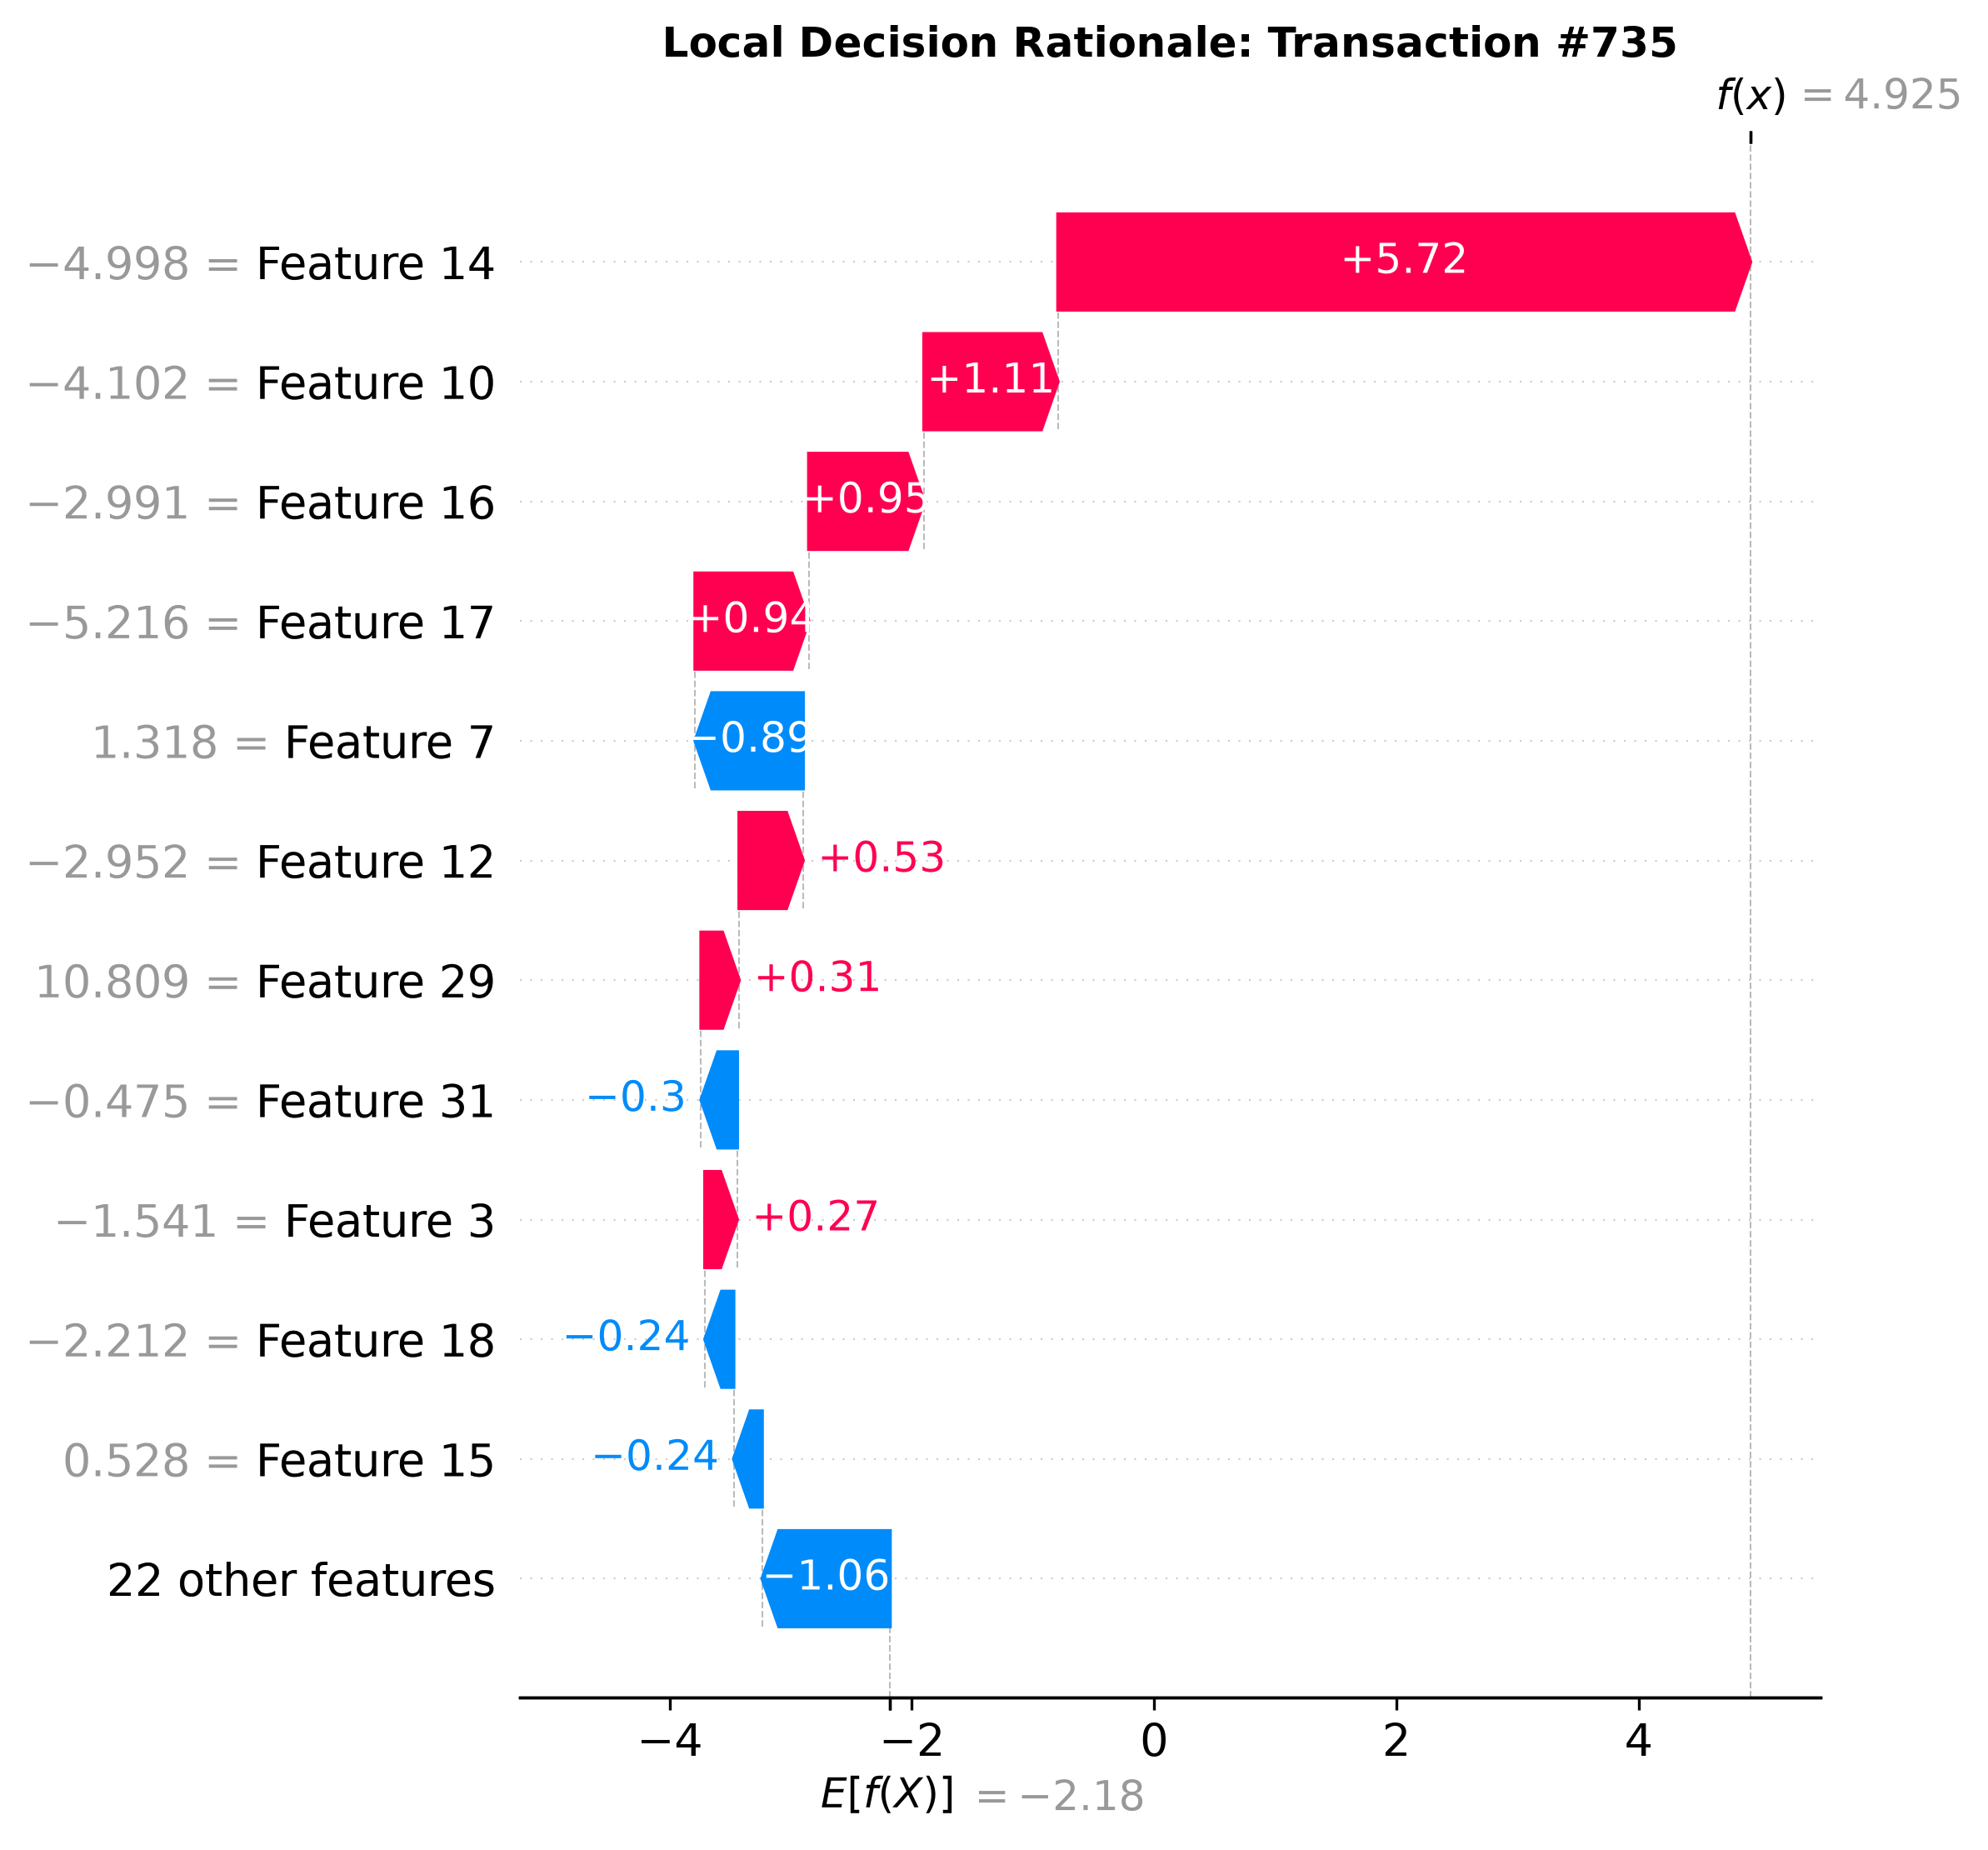

--- Confirmed Legitimate Transaction Explanation ---


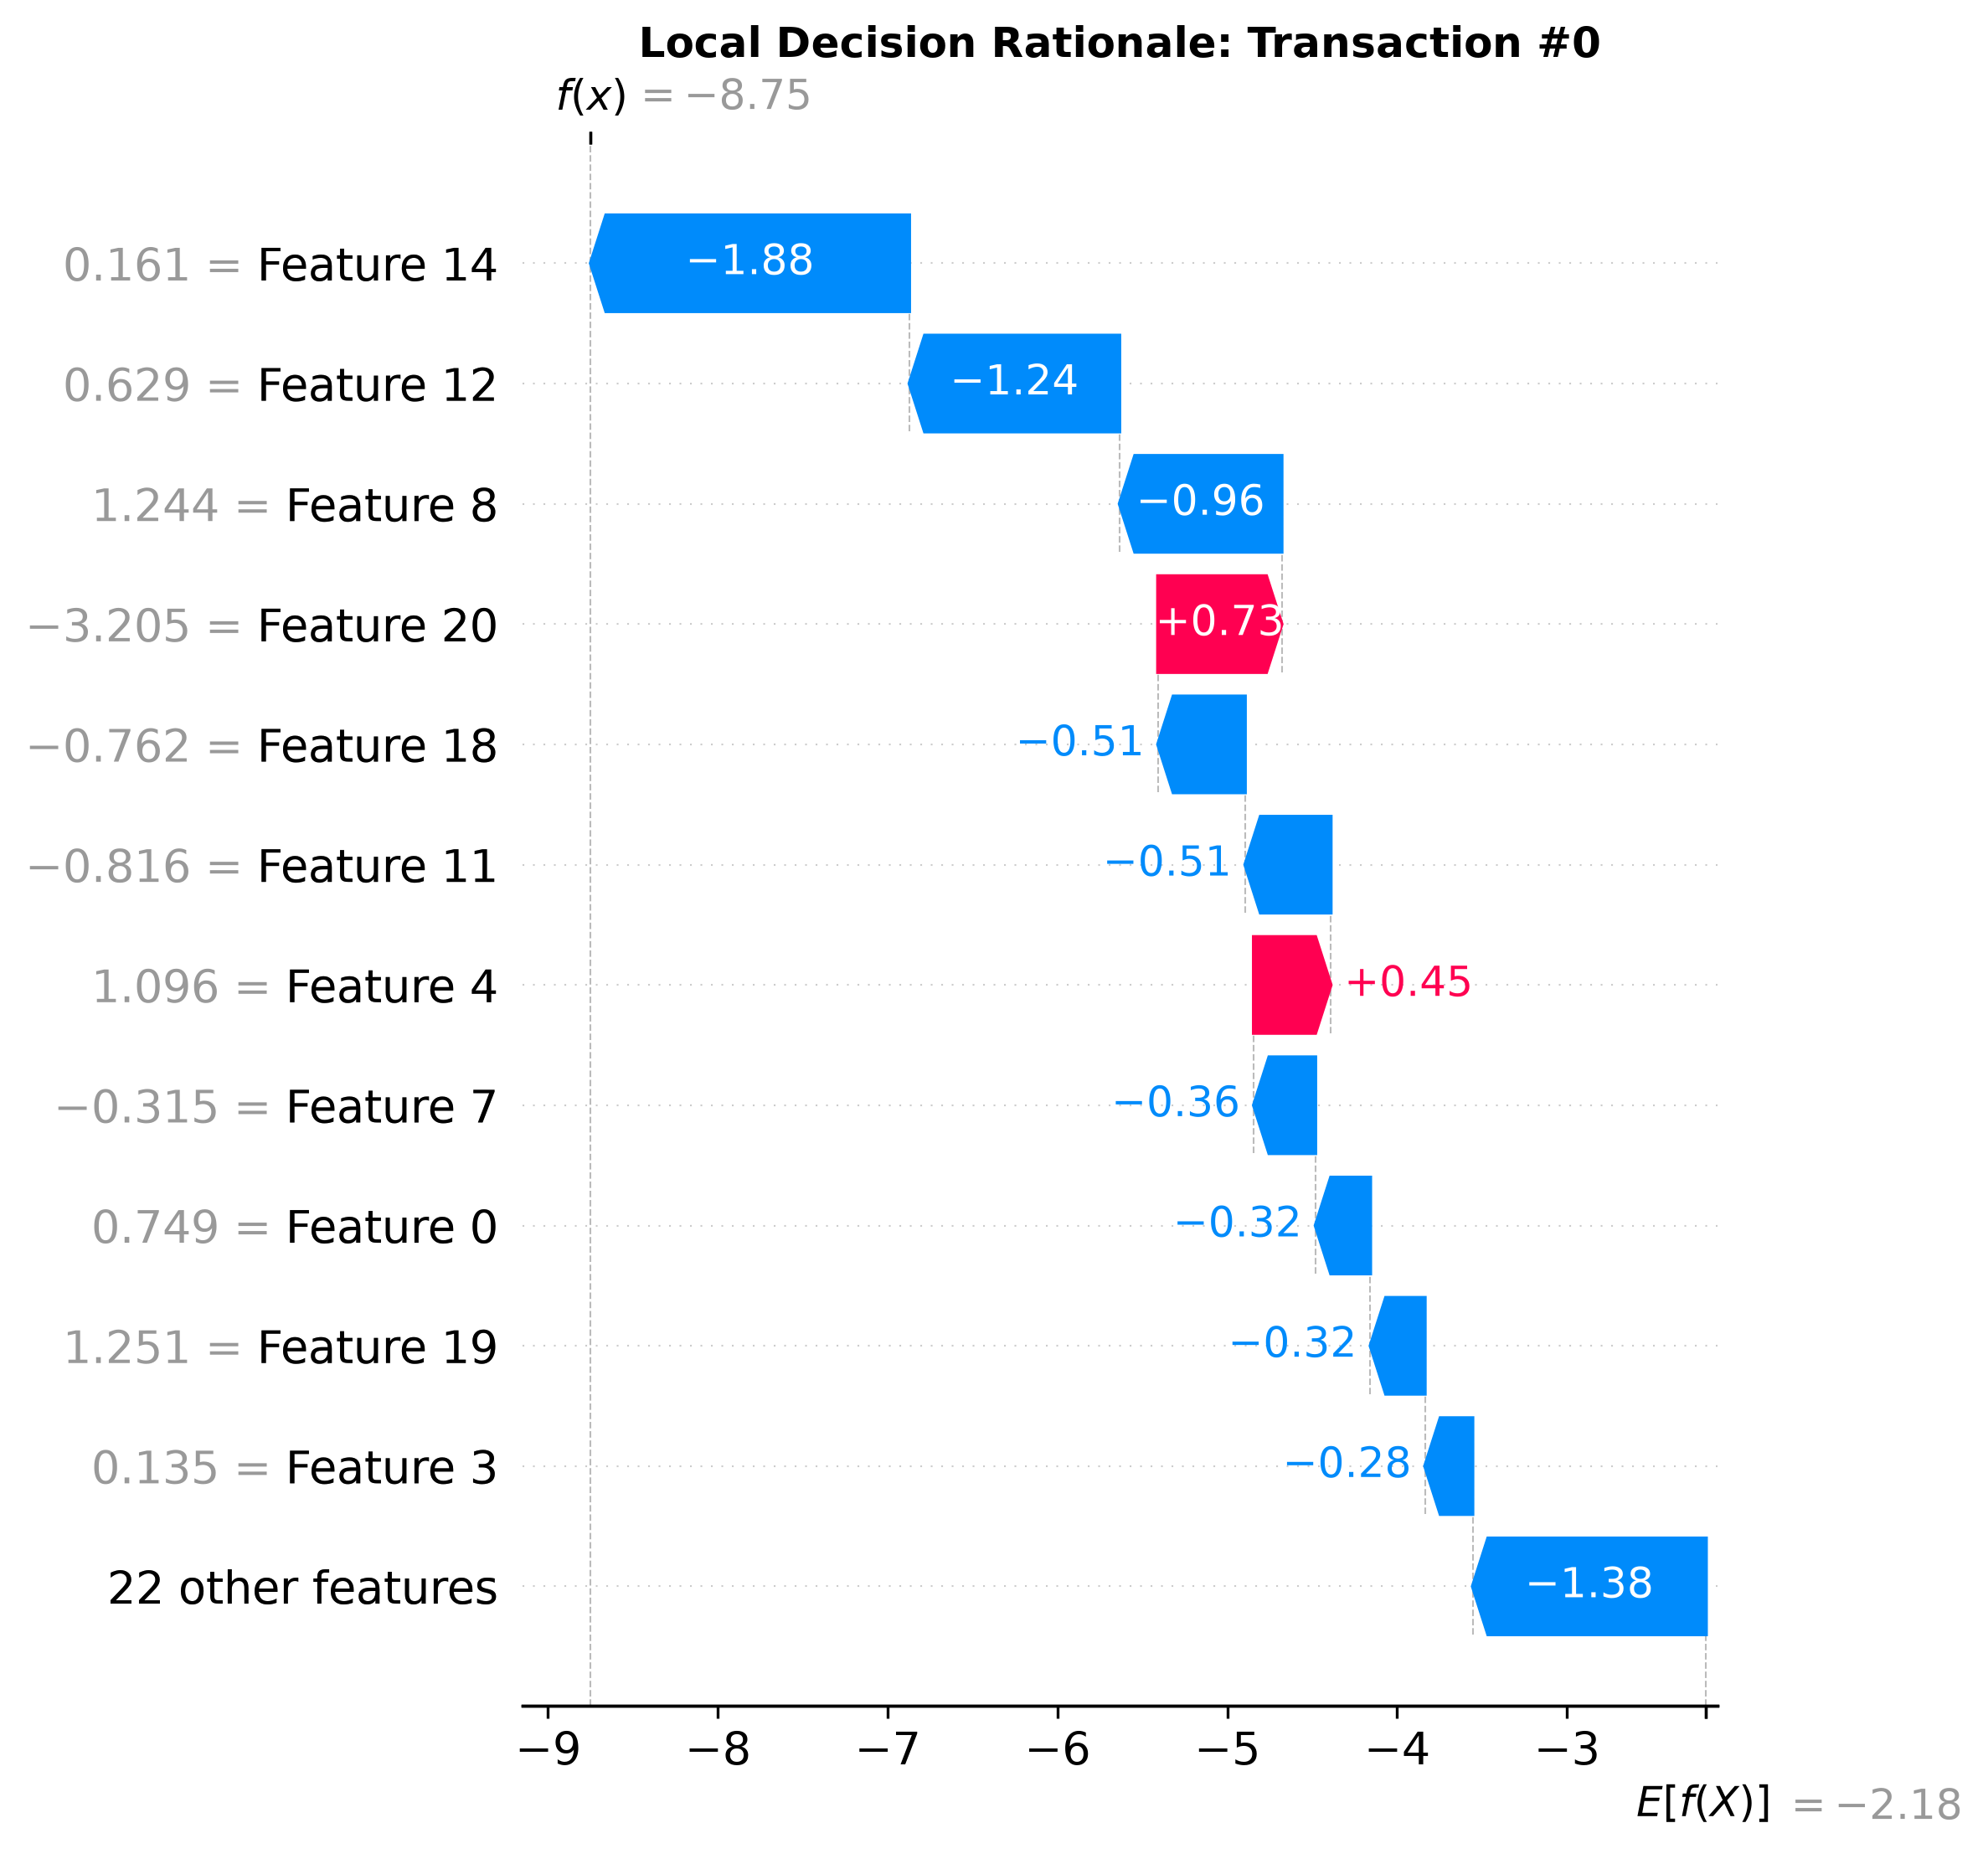

In [4]:
wf_fraud = ROOT_DIR / "results/explanations/shap_waterfall_fraud.png"
wf_norm = ROOT_DIR / "results/explanations/shap_waterfall_legitimate.png"

if wf_fraud.exists():
    print("--- Confirmed Fraud Transaction Explanation ---")
    display(Image(filename=str(wf_fraud)))

if wf_norm.exists():
    print("--- Confirmed Legitimate Transaction Explanation ---")
    display(Image(filename=str(wf_norm)))

## 4. Local Interpretable Model-agnostic Explanations (LIME)
LIME trains a local surrogate linear model in the perturbation neighborhood of the query transaction.

LIME Plot: lime_sample_735.png


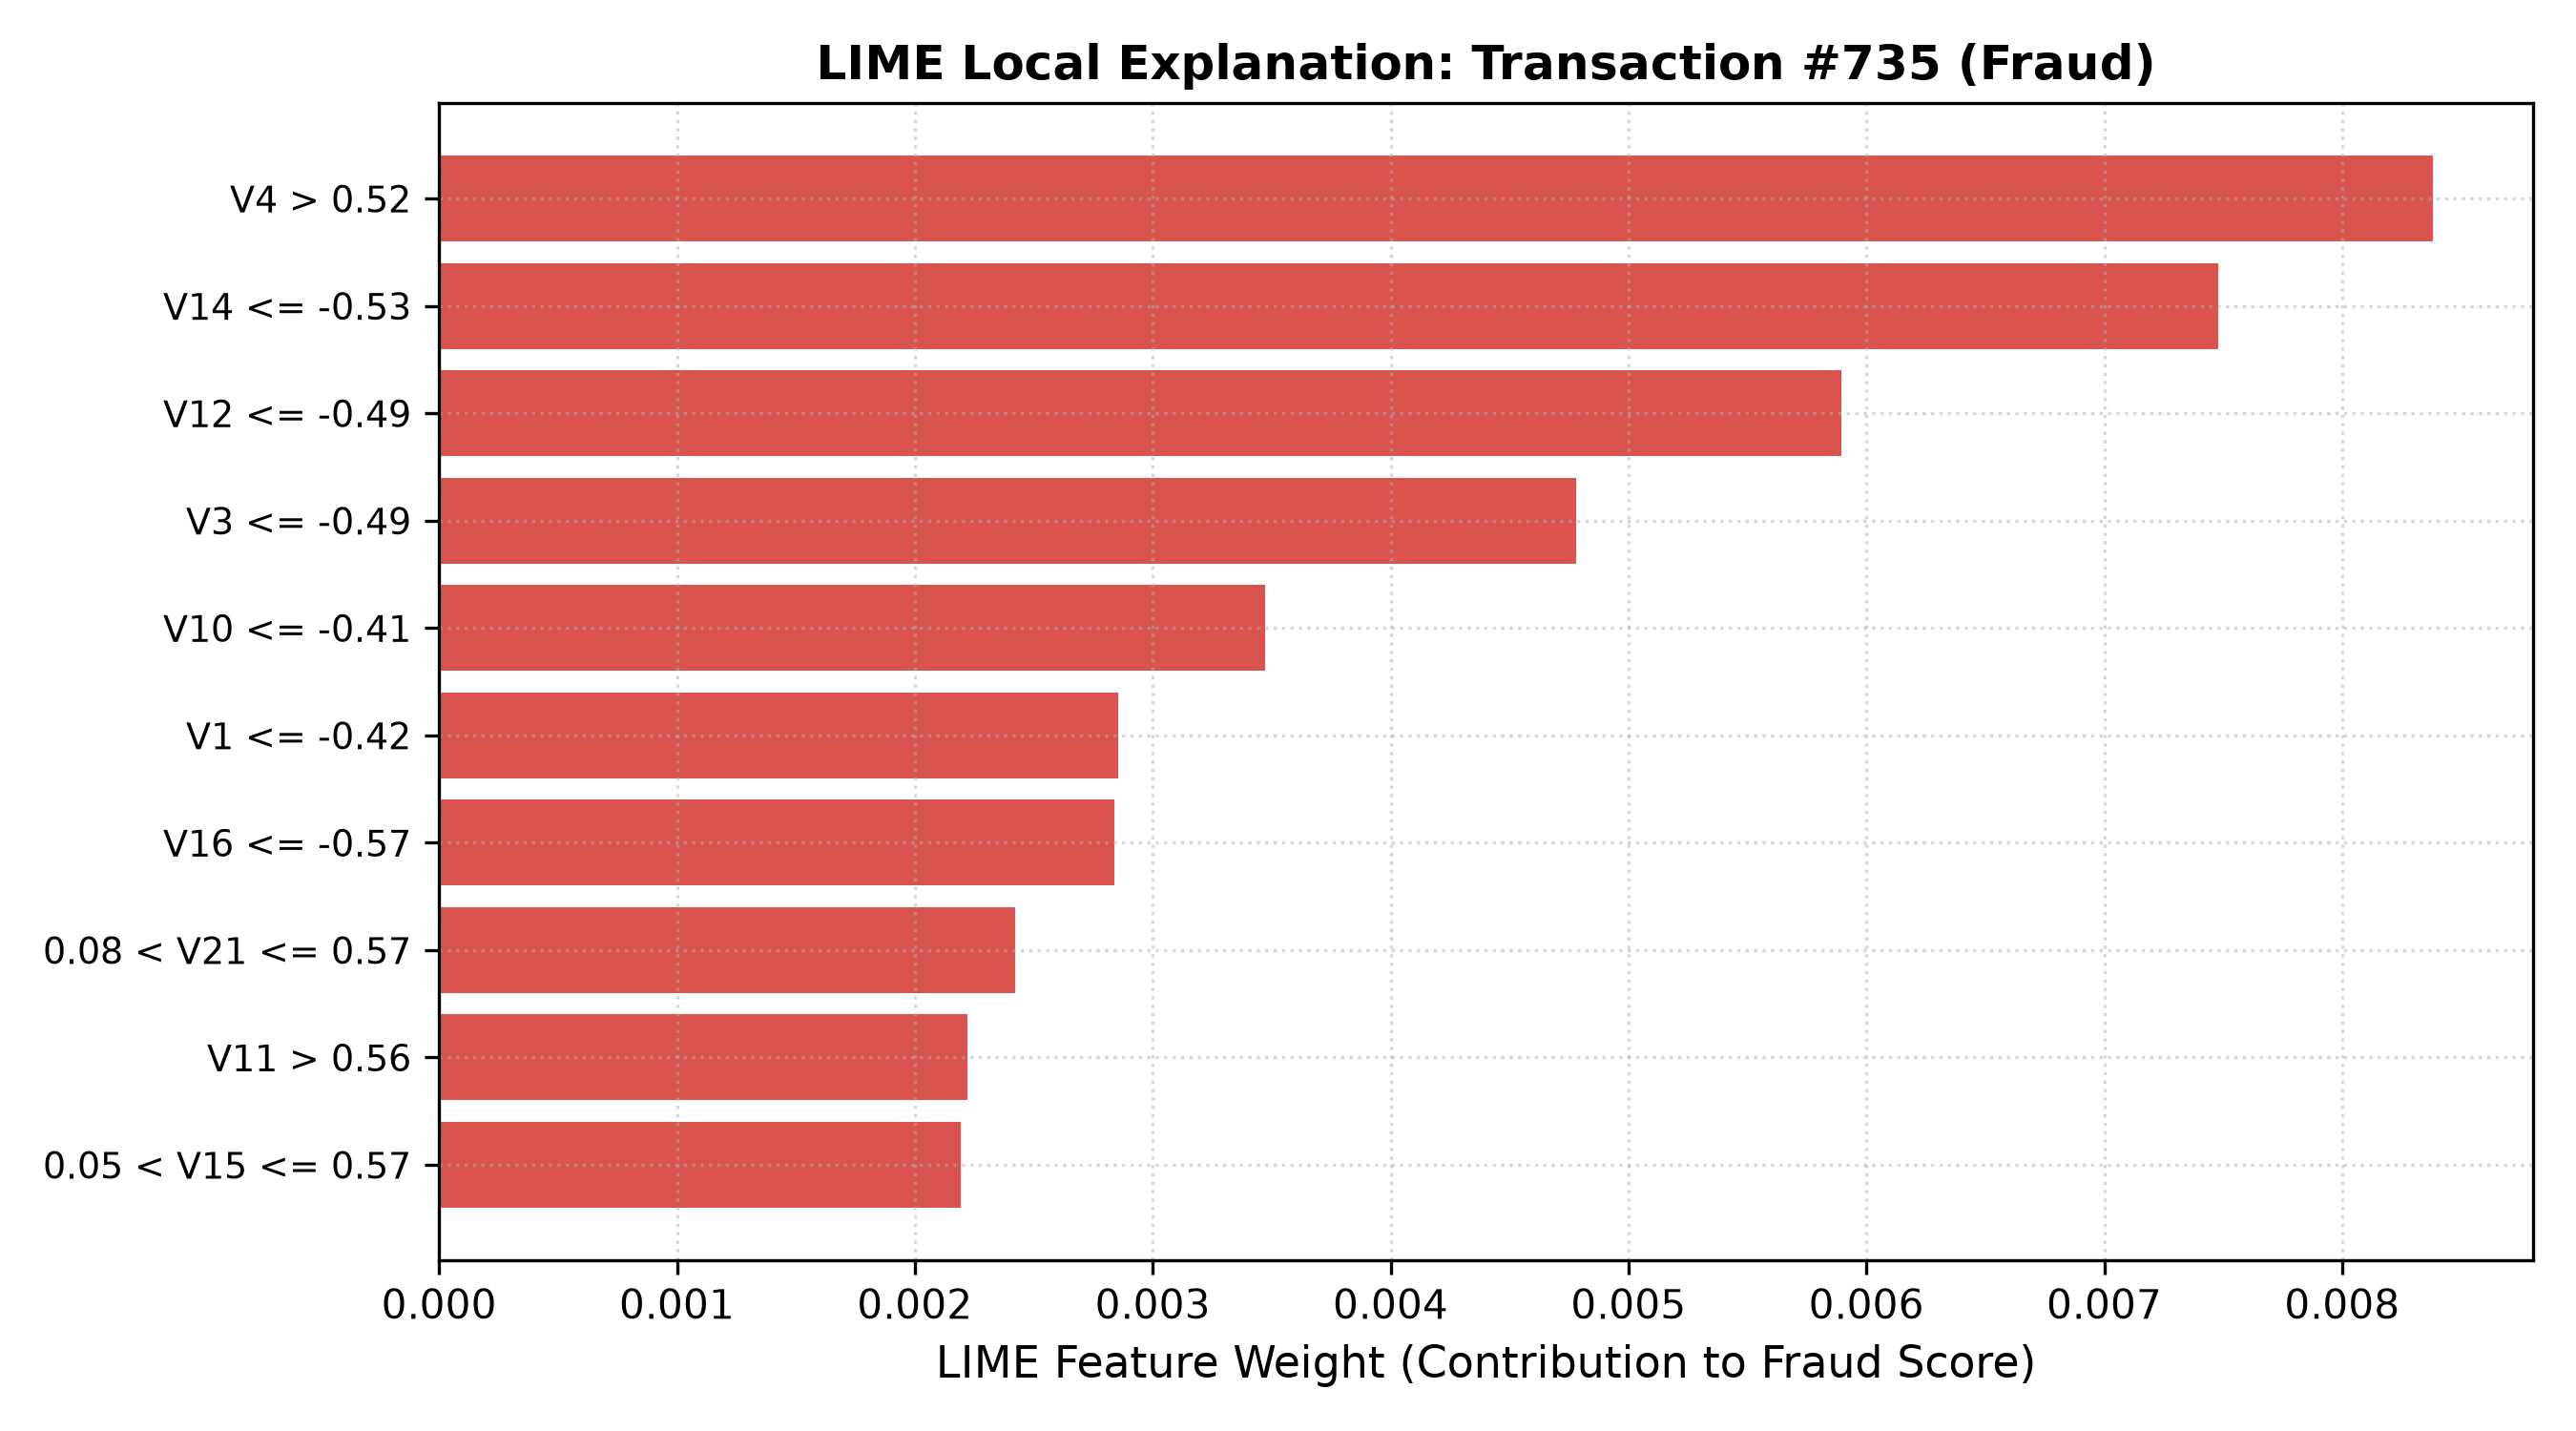

LIME Plot: lime_sample_0.png


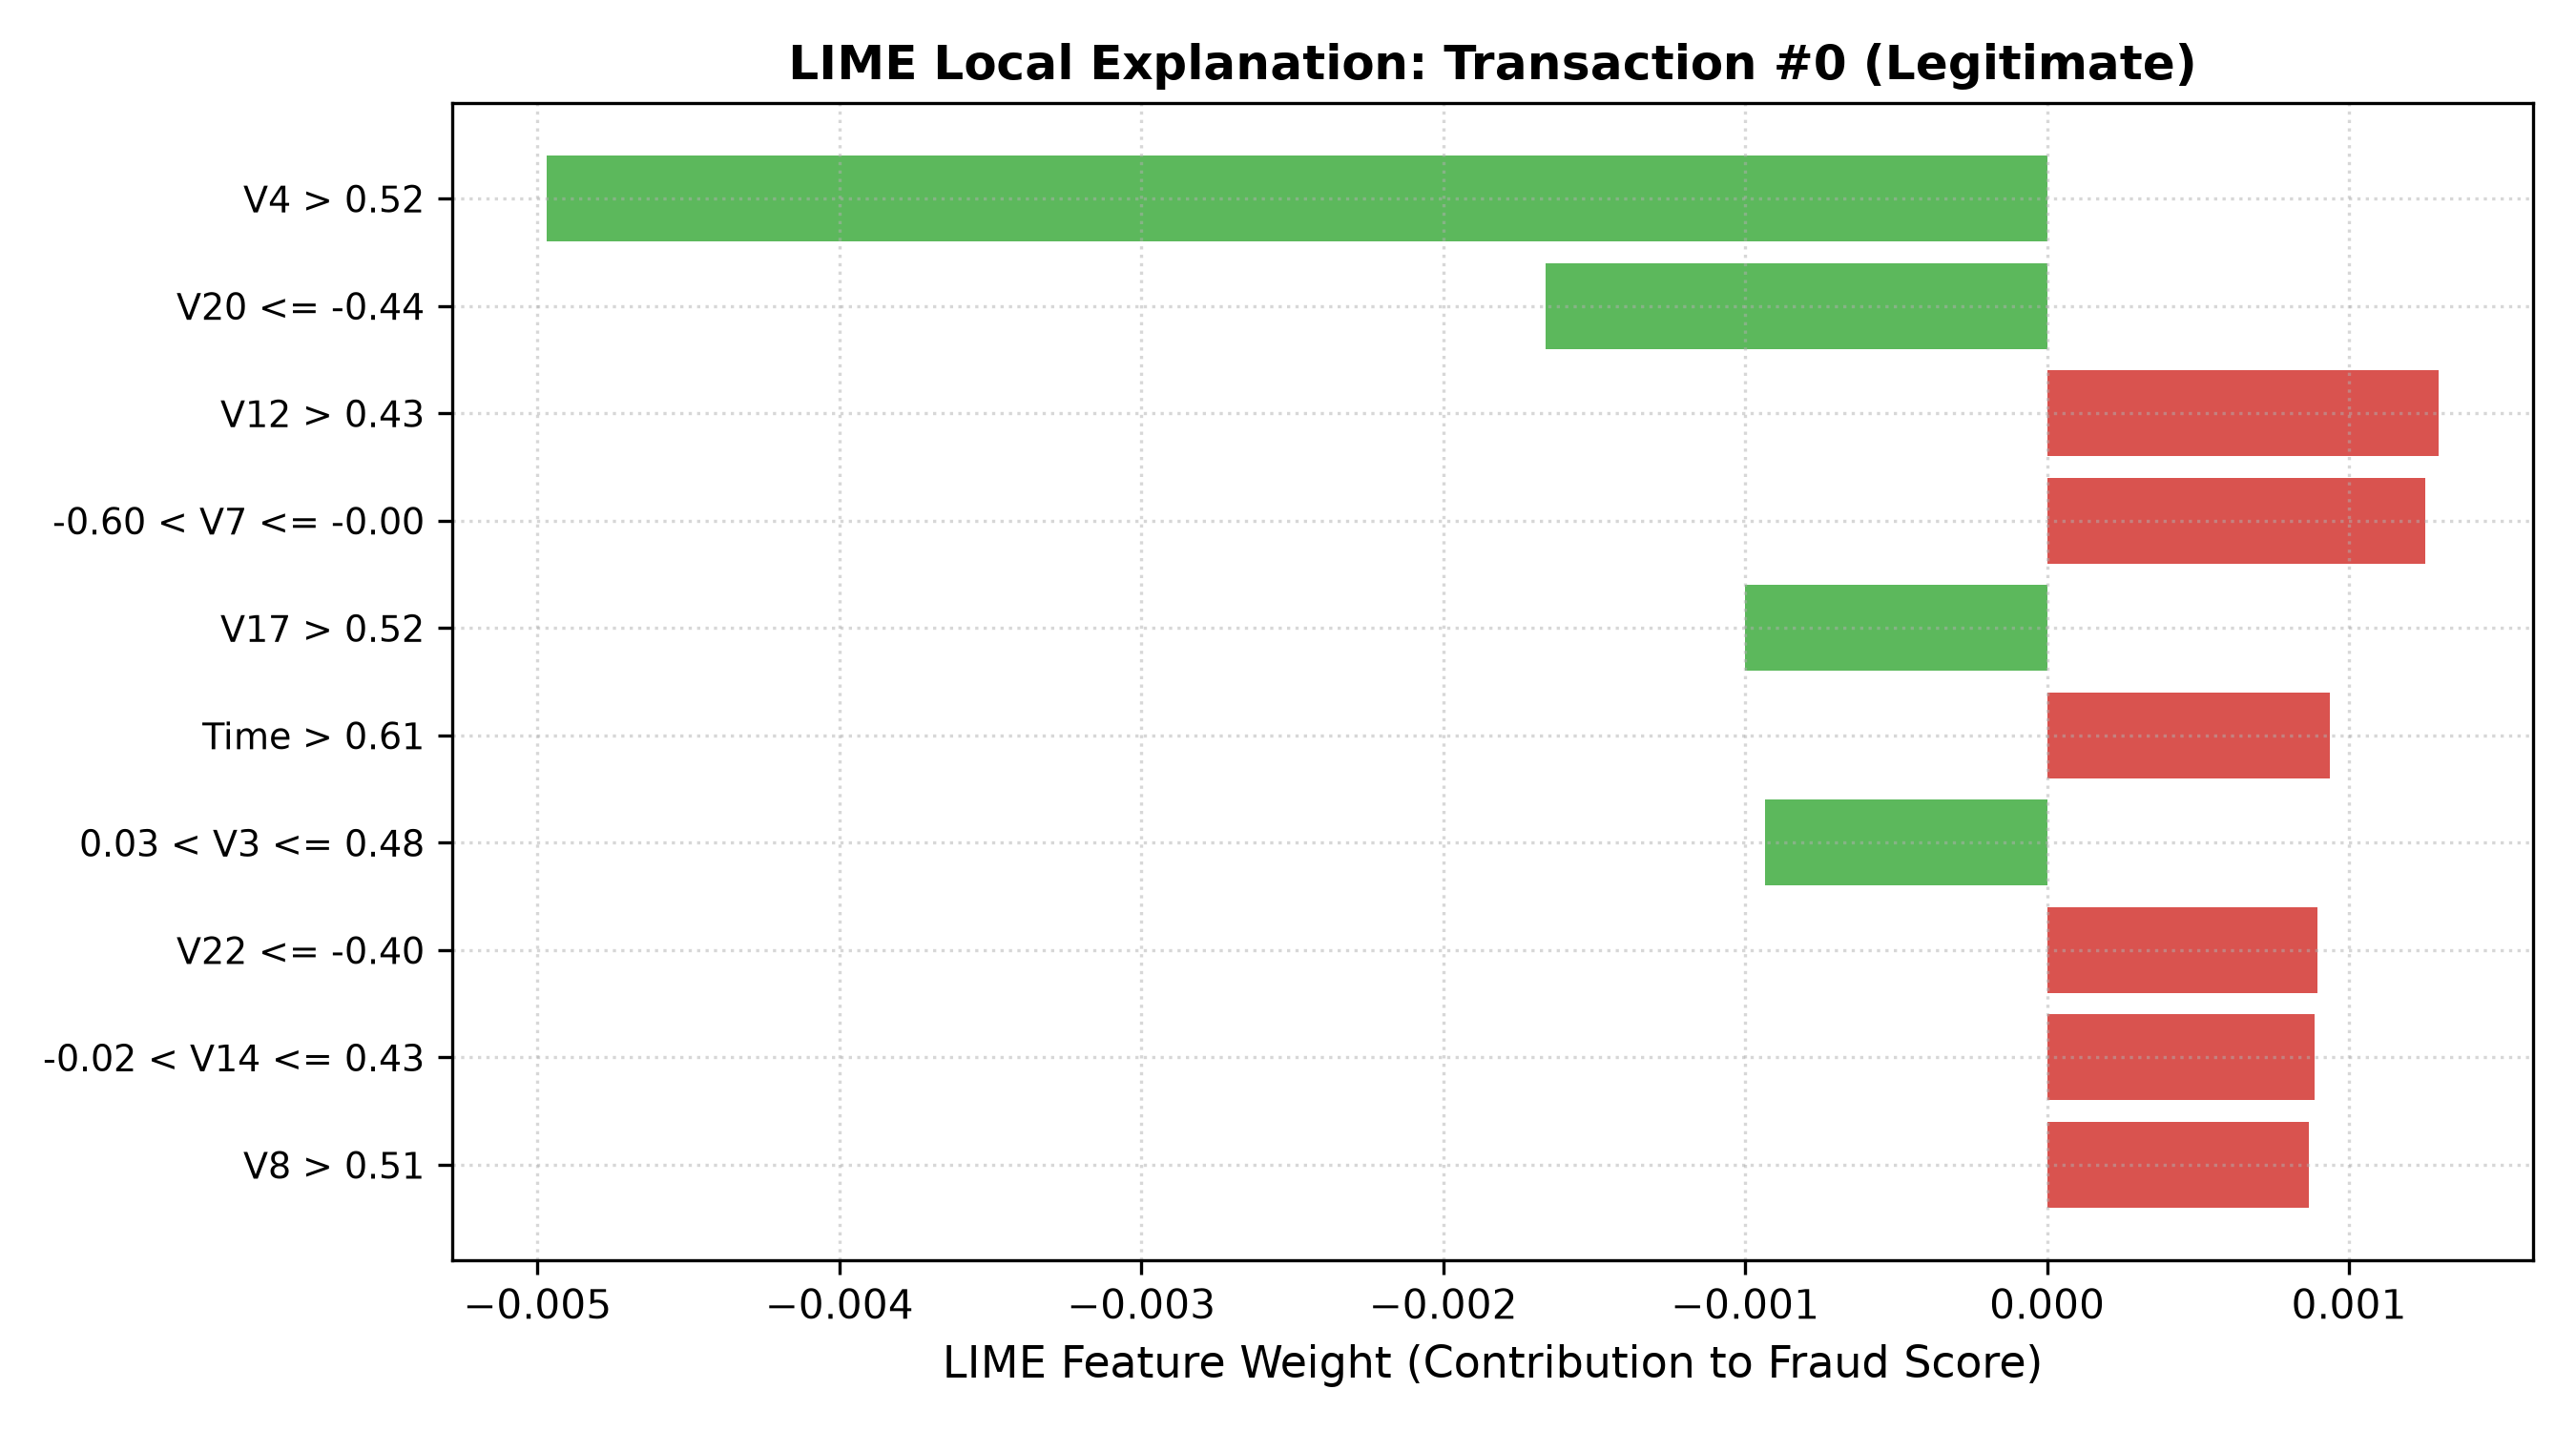

In [5]:
lime_imgs = list((ROOT_DIR / "results/explanations").glob("lime_sample_*.png"))
for p in lime_imgs[:2]:
    print(f"LIME Plot: {p.name}")
    display(Image(filename=str(p)))